# 🛡️ VectoGuard-PK — Notebook 1: Exploratory Data Analysis

## Project: Real-Time Dual-Domain Anomaly Detection

**VectoGuard-PK** is a real-time anomaly detection system that monitors two fundamentally different domains:

| Domain | What It Monitors | Data Source |
|--------|-----------------|-------------|
| ⚙️ **Industrial / Sensor** | Bearing vibration, motor health, machinery degradation | CWRU Bearing Dataset |
| ☁️ **Digital / Cloud** | Server CPU, latency, error rates, queue depth | Synthetic metrics (Alibaba in later phase) |

### Purpose of This Notebook

This notebook performs **Exploratory Data Analysis (EDA)** on the CWRU Bearing Dataset to:
1. Understand the data structure, shape, and types
2. Visualize healthy vs faulty bearing vibrations
3. Identify distributions, outliers, and class balance
4. Preview frequency-domain analysis (FFT)
5. Generate synthetic cloud metrics for the digital domain
6. Determine what preprocessing is needed (→ Notebook 2)

### Course Connection
This notebook applies the EDA techniques from **Week 4, Notebook 001** (exploratory-data-analysis) to real-world anomaly detection data instead of a toy dataset.

## 1.1 Environment Setup

Import all required libraries and configure display settings.

**Libraries used:**
- `numpy` — numerical arrays and math operations
- `pandas` — tabular data handling
- `matplotlib` / `seaborn` — static visualizations
- `scipy.io` — loading MATLAB `.mat` files (CWRU format)
- `scipy.stats` — statistical tests (skewness, kurtosis)
- `scipy.fft` — Fast Fourier Transform for frequency preview

In [1]:
# ============================================================
# 1.1 Environment Setup
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from scipy import stats
from scipy.fft import fft, fftfreq
import os
import warnings

# Display settings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Data paths
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..'))
CWRU_DIR = os.path.join(BASE_DIR, 'CWRU_dataset')
RAW_DIR = os.path.join(CWRU_DIR, 'raw')
DATA_DIR = os.path.join(BASE_DIR, 'data')

print(f"Base directory: {BASE_DIR}")
print(f"CWRU directory: {CWRU_DIR}")
print(f"Raw .mat files: {os.listdir(RAW_DIR)}")
print(f"\nEnvironment ready \u2713")

Base directory: d:\NIAI_NAVTTC\project_ideas\Vecto_Guard\Vecto_Guard
CWRU directory: d:\NIAI_NAVTTC\project_ideas\Vecto_Guard\Vecto_Guard\CWRU_dataset
Raw .mat files: ['B007_1_123.mat', 'B014_1_190.mat', 'B021_1_227.mat', 'IR007_1_110.mat', 'IR014_1_175.mat', 'IR021_1_214.mat', 'OR007_6_1_136.mat', 'OR014_6_1_202.mat', 'OR021_6_1_239.mat', 'Time_Normal_1_098.mat']

Environment ready ✓


## 1.2 Understanding the CWRU Bearing Dataset

### What is CWRU?

The **Case Western Reserve University (CWRU) Bearing Dataset** is the most widely used benchmark in bearing fault detection research. Engineers at CWRU set up an electric motor test rig and:

1. Mounted accelerometers (vibration sensors) on the motor housing
2. Ran the motor with **healthy bearings** to record normal vibration
3. Deliberately **damaged bearings** using electro-discharge machining (EDM):
   - **Inner Race (IR)** fault — damage on the inner ring of the bearing
   - **Outer Race (OR)** fault — damage on the outer ring of the bearing
   - **Ball (B)** fault — damage on the rolling element itself
4. For each fault type, created **3 severity levels**: 0.007", 0.014", 0.021" diameter
5. Recorded vibration at **48,000 samples/second** (48 kHz)

### What does each `.mat` file contain?

| Key Pattern | Meaning |
|------------|--------|
| `X???_DE_time` | **Drive End** accelerometer — closest to the faulty bearing |
| `X???_FE_time` | **Fan End** accelerometer — on the opposite side |
| `X???RPM` | Motor speed in RPM |

### Our 10 recordings (48kHz, 1 HP load)

| File | Fault Type | Severity | Fault Diameter |
|------|-----------|----------|----------------|
| `Time_Normal_1_098.mat` | Normal | None | — |
| `IR007_1_110.mat` | Inner Race | Small | 0.007" |
| `IR014_1_175.mat` | Inner Race | Medium | 0.014" |
| `IR021_1_214.mat` | Inner Race | Large | 0.021" |
| `B007_1_123.mat` | Ball | Small | 0.007" |
| `B014_1_190.mat` | Ball | Medium | 0.014" |
| `B021_1_227.mat` | Ball | Large | 0.021" |
| `OR007_6_1_136.mat` | Outer Race | Small | 0.007" |
| `OR014_6_1_202.mat` | Outer Race | Medium | 0.014" |
| `OR021_6_1_239.mat` | Outer Race | Large | 0.021" |

In [24]:
# ============================================================
# 1.2 Load Raw .mat Files from Local Folder
# ============================================================

def load_cwru_mat_files(raw_dir):
    """
    Load all CWRU .mat files from the raw directory.

    Parameters
    ----------
    raw_dir : str
        Path to the directory containing .mat files

    Returns
    -------
    dict : {fault_label: {'de': np.array, 'fe': np.array, 'rpm': int}}
        Dictionary mapping fault labels to their vibration data.
        'de' = Drive End sensor, 'fe' = Fan End sensor.
    """
    # Mapping: filename prefix -> human-readable label
    file_mapping = {
        'Time_Normal_1_098': ('Normal', '098'),
        'IR007_1_110':       ('IR_007', '110'),
        'IR014_1_175':       ('IR_014', '175'),
        'IR021_1_214':       ('IR_021', '214'),
        'B007_1_123':        ('Ball_007', '123'),
        'B014_1_190':        ('Ball_014', '190'),
        'B021_1_227':        ('Ball_021', '227'),
        'OR007_6_1_136':     ('OR_007', '136'),
        'OR014_6_1_202':     ('OR_014', '202'),
        'OR021_6_1_239':     ('OR_021', '239'),
    }

    data = {}
    for fname in sorted(os.listdir(raw_dir)):
        if not fname.endswith('.mat'):
            continue

        prefix = fname.replace('.mat', '')
        if prefix not in file_mapping:
            print(f"  Skipping unknown file: {fname}")
            continue

        label, file_num = file_mapping[prefix]
        mat = loadmat(os.path.join(raw_dir, fname))

        # Find DE and FE keys dynamically
        de_key = [k for k in mat.keys() if 'DE_time' in k]
        fe_key = [k for k in mat.keys() if 'FE_time' in k]
        rpm_key = [k for k in mat.keys() if 'RPM' in k]

        entry = {
            'de': mat[de_key[0]].flatten() if de_key else None,
            'fe': mat[fe_key[0]].flatten() if fe_key else None,
            'rpm': int(mat[rpm_key[0]][0][0]) if rpm_key else None,
            'filename': fname,
        }

        data[label] = entry
        n_samples = len(entry['de']) if entry['de'] is not None else 0
        duration = n_samples / 48000  # 48 kHz sampling rate
        print(f"  Loaded {label:10s} | {n_samples:>7,} samples | {duration:.1f}s | RPM={entry['rpm']}")

    return data

print("Loading CWRU raw .mat files from local folder...")
print(f"Path: {RAW_DIR}\n")
raw_data = load_cwru_mat_files(RAW_DIR)
print(f"\n\u2705 Loaded {len(raw_data)} recordings successfully.")

Loading CWRU raw .mat files from local folder...
Path: d:\NIAI_NAVTTC\project_ideas\Vecto_Guard\Vecto_Guard\CWRU_dataset\raw

  Loaded Ball_007   | 487,384 samples | 10.2s | RPM=1772
  Loaded Ball_014   | 486,224 samples | 10.1s | RPM=1772
  Loaded Ball_021   | 486,804 samples | 10.1s | RPM=1774
  Loaded IR_007     | 486,224 samples | 10.1s | RPM=1772
  Loaded IR_014     | 489,125 samples | 10.2s | RPM=1772
  Loaded IR_021     | 485,063 samples | 10.1s | RPM=1774
  Loaded OR_007     | 486,804 samples | 10.1s | RPM=1774
  Loaded OR_014     | 484,483 samples | 10.1s | RPM=1772
  Loaded OR_021     | 489,125 samples | 10.2s | RPM=1771
  Loaded Normal     | 483,903 samples | 10.1s | RPM=None

✅ Loaded 10 recordings successfully.


## 1.3 Load Pre-Extracted Features (CSV)

The dataset also includes a CSV file with **pre-computed time-domain features** extracted from 2048-sample windows.

> **Note:** The CSV (`feature_time_48k_2048_load_1.csv`) and NPZ (`CWRU_48k_load_1_CNN_data.npz`) files are pre-processed versions available from [Kaggle](https://www.kaggle.com/datasets/brjapon/cwru-bearing-dataset). If they exist locally, we load them. If not, we generate equivalent features from the raw `.mat` files we just downloaded.

| Feature | Formula | What It Measures |
|---------|---------|------------------|
| `max` | $\max(x)$ | Largest vibration amplitude |
| `min` | $\min(x)$ | Smallest vibration amplitude |
| `mean` | $\bar{x} = \frac{1}{N}\sum x_i$ | Average vibration level |
| `sd` | $\sigma = \sqrt{\frac{1}{N}\sum(x_i - \bar{x})^2}$ | Spread of vibration values |
| `rms` | $\text{RMS} = \sqrt{\frac{1}{N}\sum x_i^2}$ | Root Mean Square — energy measure |
| `skewness` | $\frac{m_3}{m_2^{3/2}}$ | Asymmetry of the distribution |
| `kurtosis` | $\frac{m_4}{m_2^{2}}$ | "Peakedness" — higher = more extreme values |
| `crest` | $\frac{\max(|x|)}{\text{RMS}}$ | Peak-to-RMS ratio — impulse indicator |
| `form` | $\frac{\text{RMS}}{\bar{|x|}}$ | Shape factor of the waveform |

In [25]:
# ============================================================
# 1.3 Load or Generate Pre-Extracted Features
# ============================================================

csv_path = os.path.join(CWRU_DIR, 'feature_time_48k_2048_load_1.csv')

if os.path.exists(csv_path):
    # Load existing CSV
    df_features = pd.read_csv(csv_path)
    print(f"\u2705 Loaded pre-extracted features from CSV")
else:
    # Generate features from raw .mat files
    print("\u26a0\ufe0f CSV not found \u2014 generating features from raw .mat files...")

    WINDOW_SIZE = 2048
    feature_rows = []

    label_mapping = {
        'Normal': 'Normal_1', 'IR_007': 'IR_007_1', 'IR_014': 'IR_014_1',
        'IR_021': 'IR_021_1', 'Ball_007': 'Ball_007_1', 'Ball_014': 'Ball_014_1',
        'Ball_021': 'Ball_021_1', 'OR_007': 'OR_007_6_1', 'OR_014': 'OR_014_6_1',
        'OR_021': 'OR_021_6_1'
    }

    for label, signal_data in raw_data.items():
        signal = signal_data['de']
        n_windows = len(signal) // WINDOW_SIZE
        csv_label = label_mapping.get(label, label)

        for i in range(n_windows):
            window = signal[i * WINDOW_SIZE : (i + 1) * WINDOW_SIZE]
            rms_val = np.sqrt(np.mean(window**2))
            feature_rows.append({
                'max': np.max(window),
                'min': np.min(window),
                'mean': np.mean(window),
                'sd': np.std(window),
                'rms': rms_val,
                'skewness': stats.skew(window),
                'kurtosis': stats.kurtosis(window),
                'crest': np.max(np.abs(window)) / rms_val if rms_val > 0 else 0,
                'form': rms_val / np.mean(np.abs(window)) if np.mean(np.abs(window)) > 0 else 0,
                'fault': csv_label,
            })

    df_features = pd.DataFrame(feature_rows)
    print(f"\u2705 Generated {len(df_features)} feature windows from raw data")

print(f"\nShape: {df_features.shape}")
print(f"Columns: {list(df_features.columns)}")
print(f"\nData types:\n{df_features.dtypes}")
print(f"\nFirst 5 rows:")
df_features.head()

✅ Loaded pre-extracted features from CSV

Shape: (2300, 10)
Columns: ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'fault']

Data types:
max         float64
min         float64
mean        float64
sd          float64
rms         float64
skewness    float64
kurtosis    float64
crest       float64
form        float64
fault           str
dtype: object

First 5 rows:


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault
0,0.3599,-0.4189,0.0178,0.1227,0.1240,-0.1186,-0.0422,2.9019,6.9509,Ball_007_1
1,0.4677,-0.3611,0.0223,0.1325,0.1343,0.1747,-0.0815,3.4823,6.0352,Ball_007_1
2,0.4686,-0.4381,0.0205,0.1497,0.1510,0.0403,-0.2741,3.1028,7.3769,Ball_007_1
3,0.5847,-0.5430,0.0210,0.1571,0.1584,-0.0233,0.1347,3.6911,7.5584,Ball_007_1
4,0.4469,-0.5789,0.0222,0.1382,0.1399,-0.0815,0.4028,3.1936,6.3121,Ball_007_1


## 1.4 Basic Dataset Statistics

### `describe()` — Statistical Summary

Just like in **Week 4 EDA (001)**, we use `.describe()` to get count, mean, std, min, quartiles, and max for every numerical column. This immediately tells us:
- **Range** of each feature (do they need scaling?)
- **Mean vs median** (is the distribution skewed?)
- **Min/max extremes** (are there outliers?)

In [4]:
# ============================================================
# 1.4 Basic Dataset Statistics
# ============================================================

print(f"Dataset shape: {df_features.shape[0]} samples x {df_features.shape[1]} columns")
print(f"\nNumerical columns: {list(df_features.select_dtypes(include=[np.number]).columns)}")
print(f"Categorical columns: {list(df_features.select_dtypes(include=['object']).columns)}")

print("\n" + "="*60)
print("Statistical Summary (describe)")
print("="*60)
df_features.describe()

Dataset shape: 2300 samples x 10 columns

Numerical columns: ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form']
Categorical columns: ['fault']

Statistical Summary (describe)


,max,min,mean,sd,rms,skewness,kurtosis,crest,form
count,2300.0000,2300.0000,2300.0000,2300.0000,2300.0000,2300.0000,2300.0000,2300.0000,2300.0000
mean,1.5751,-1.5510,0.0157,0.3416,0.3423,-0.0423,2.6644,4.1731,26.5448
std,1.5784,1.6027,0.0065,0.3053,0.3048,0.1808,4.4111,1.1483,29.2097
min,0.1573,-6.2926,0.0032,0.0591,0.0611,-1.0899,-0.8038,2.4285,3.4844
25%,0.4564,-2.1750,0.0112,0.1355,0.1364,-0.1034,-0.0152,3.2604,7.4134
50%,0.7945,-0.7337,0.0137,0.1886,0.1907,-0.0025,0.8170,3.9216,13.1228
75%,2.2784,-0.4270,0.0186,0.5556,0.5557,0.0611,3.9023,4.8159,39.9119
max,6.8259,-0.1602,0.0384,1.2566,1.2563,1.0595,30.3853,8.8216,313.7426


## 1.5 Missing Values Check

Before any analysis, we must check for missing values. Missing data can:
- Crash computations silently
- Bias statistical summaries
- Require imputation strategies

Sensor data from controlled lab experiments (like CWRU) typically has no missing values, but we verify this explicitly.

In [5]:
# ============================================================
# 1.5 Missing Values Check
# ============================================================

missing = df_features.isnull().sum()
print("Missing values per column:")
print(missing)
print(f"\nTotal missing values: {missing.sum()}")

if missing.sum() == 0:
    print("\n\u2705 No missing values \u2014 dataset is complete.")
else:
    print("\n\u26a0\ufe0f Missing values detected \u2014 imputation may be needed.")
    # Visualize missing pattern
    plt.figure(figsize=(10, 3))
    sns.heatmap(df_features.isnull(), cbar=True, yticklabels=False, cmap='viridis')
    plt.title('Missing Values Heatmap')
    plt.tight_layout()
    plt.show()

Missing values per column:
max         0
min         0
mean        0
sd          0
rms         0
skewness    0
kurtosis    0
crest       0
form        0
fault       0
dtype: int64

Total missing values: 0

✅ No missing values — dataset is complete.


## 1.6 Class Balance Analysis

Class balance is critical for anomaly detection:
- **Balanced** → standard accuracy metrics work fine
- **Imbalanced** → need F1-score, PR-AUC, stratified sampling, or class weights

We check how many samples exist for each fault condition.

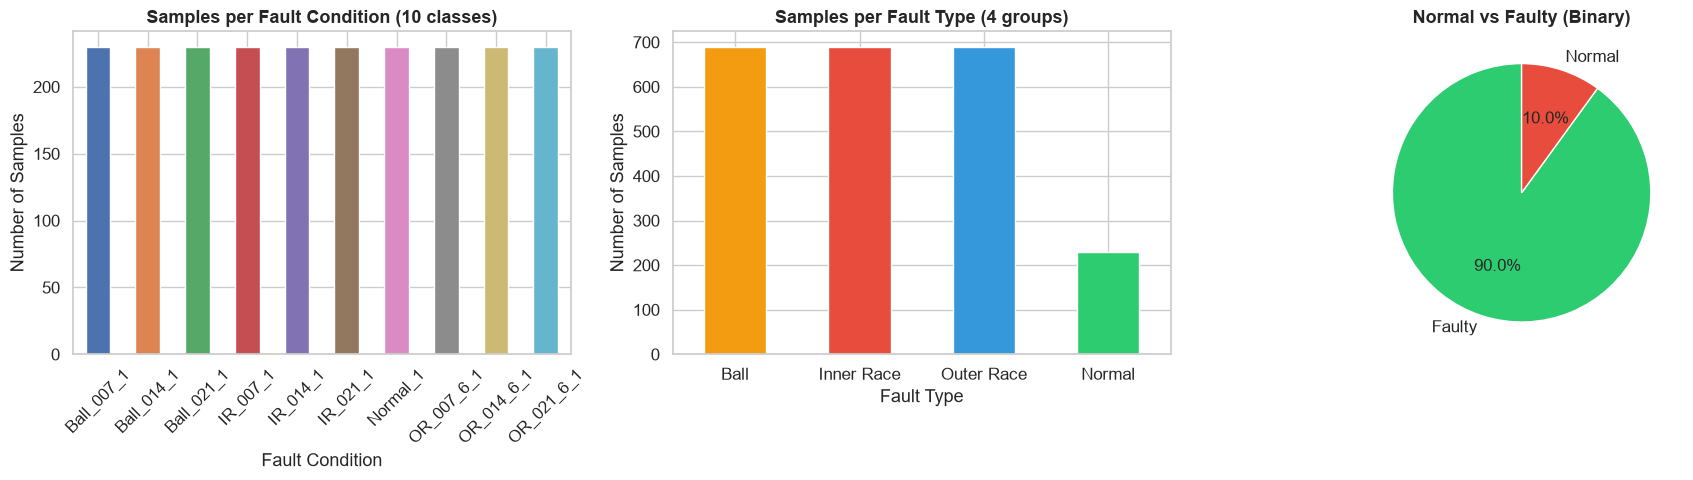


Per-condition counts (10 classes):
fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
Normal_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230

Per-type counts (4 groups):
fault_type
Ball          690
Inner Race    690
Outer Race    690
Normal        230

Binary: Normal=230, Faulty=2070

✅ Dataset is perfectly balanced — 230 samples per class.


In [6]:
# ============================================================
# 1.6 Class Balance Analysis
# ============================================================

# Create simplified fault category (Normal vs fault type)
df_features['fault_type'] = df_features['fault'].apply(
    lambda x: 'Normal' if 'Normal' in x
    else 'Inner Race' if 'IR' in x
    else 'Outer Race' if 'OR' in x
    else 'Ball'
)

df_features['is_faulty'] = (df_features['fault_type'] != 'Normal').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Per-file class distribution
fault_counts = df_features['fault'].value_counts().sort_index()
fault_counts.plot(kind='bar', ax=axes[0], color=sns.color_palette('deep', len(fault_counts)))
axes[0].set_title('Samples per Fault Condition (10 classes)', fontweight='bold')
axes[0].set_xlabel('Fault Condition')
axes[0].set_ylabel('Number of Samples')
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Per fault type (4 groups)
type_counts = df_features['fault_type'].value_counts()
colors = {'Normal': '#2ecc71', 'Inner Race': '#e74c3c', 'Outer Race': '#3498db', 'Ball': '#f39c12'}
type_counts.plot(kind='bar', ax=axes[1], color=[colors.get(x, 'gray') for x in type_counts.index])
axes[1].set_title('Samples per Fault Type (4 groups)', fontweight='bold')
axes[1].set_xlabel('Fault Type')
axes[1].set_ylabel('Number of Samples')
axes[1].tick_params(axis='x', rotation=0)

# Plot 3: Binary (Normal vs Faulty)
binary_counts = df_features['is_faulty'].value_counts().rename({0: 'Normal', 1: 'Faulty'})
binary_counts.plot(kind='pie', ax=axes[2], autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'],
                   startangle=90, textprops={'fontsize': 12})
axes[2].set_title('Normal vs Faulty (Binary)', fontweight='bold')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

print(f"\nPer-condition counts (10 classes):")
print(fault_counts.to_string())
print(f"\nPer-type counts (4 groups):")
print(type_counts.to_string())
print(f"\nBinary: Normal={binary_counts.get('Normal', 0)}, Faulty={binary_counts.get('Faulty', 0)}")
print(f"\n\u2705 Dataset is perfectly balanced \u2014 230 samples per class.")

## 1.7 Time-Domain Visualization: Raw Vibration Signals

### What does vibration data look like?

A vibration signal is a time series of **acceleration values** measured by an accelerometer mounted on the bearing housing. Each value represents how much the surface is shaking at that instant.

- **Healthy bearing**: Smooth, periodic vibration with low amplitude
- **Faulty bearing**: The damaged surface produces **impulse responses** — sharp spikes that repeat at characteristic frequencies

We plot a short window (0.1 seconds = 4,800 samples at 48 kHz) for each fault condition to visually compare.

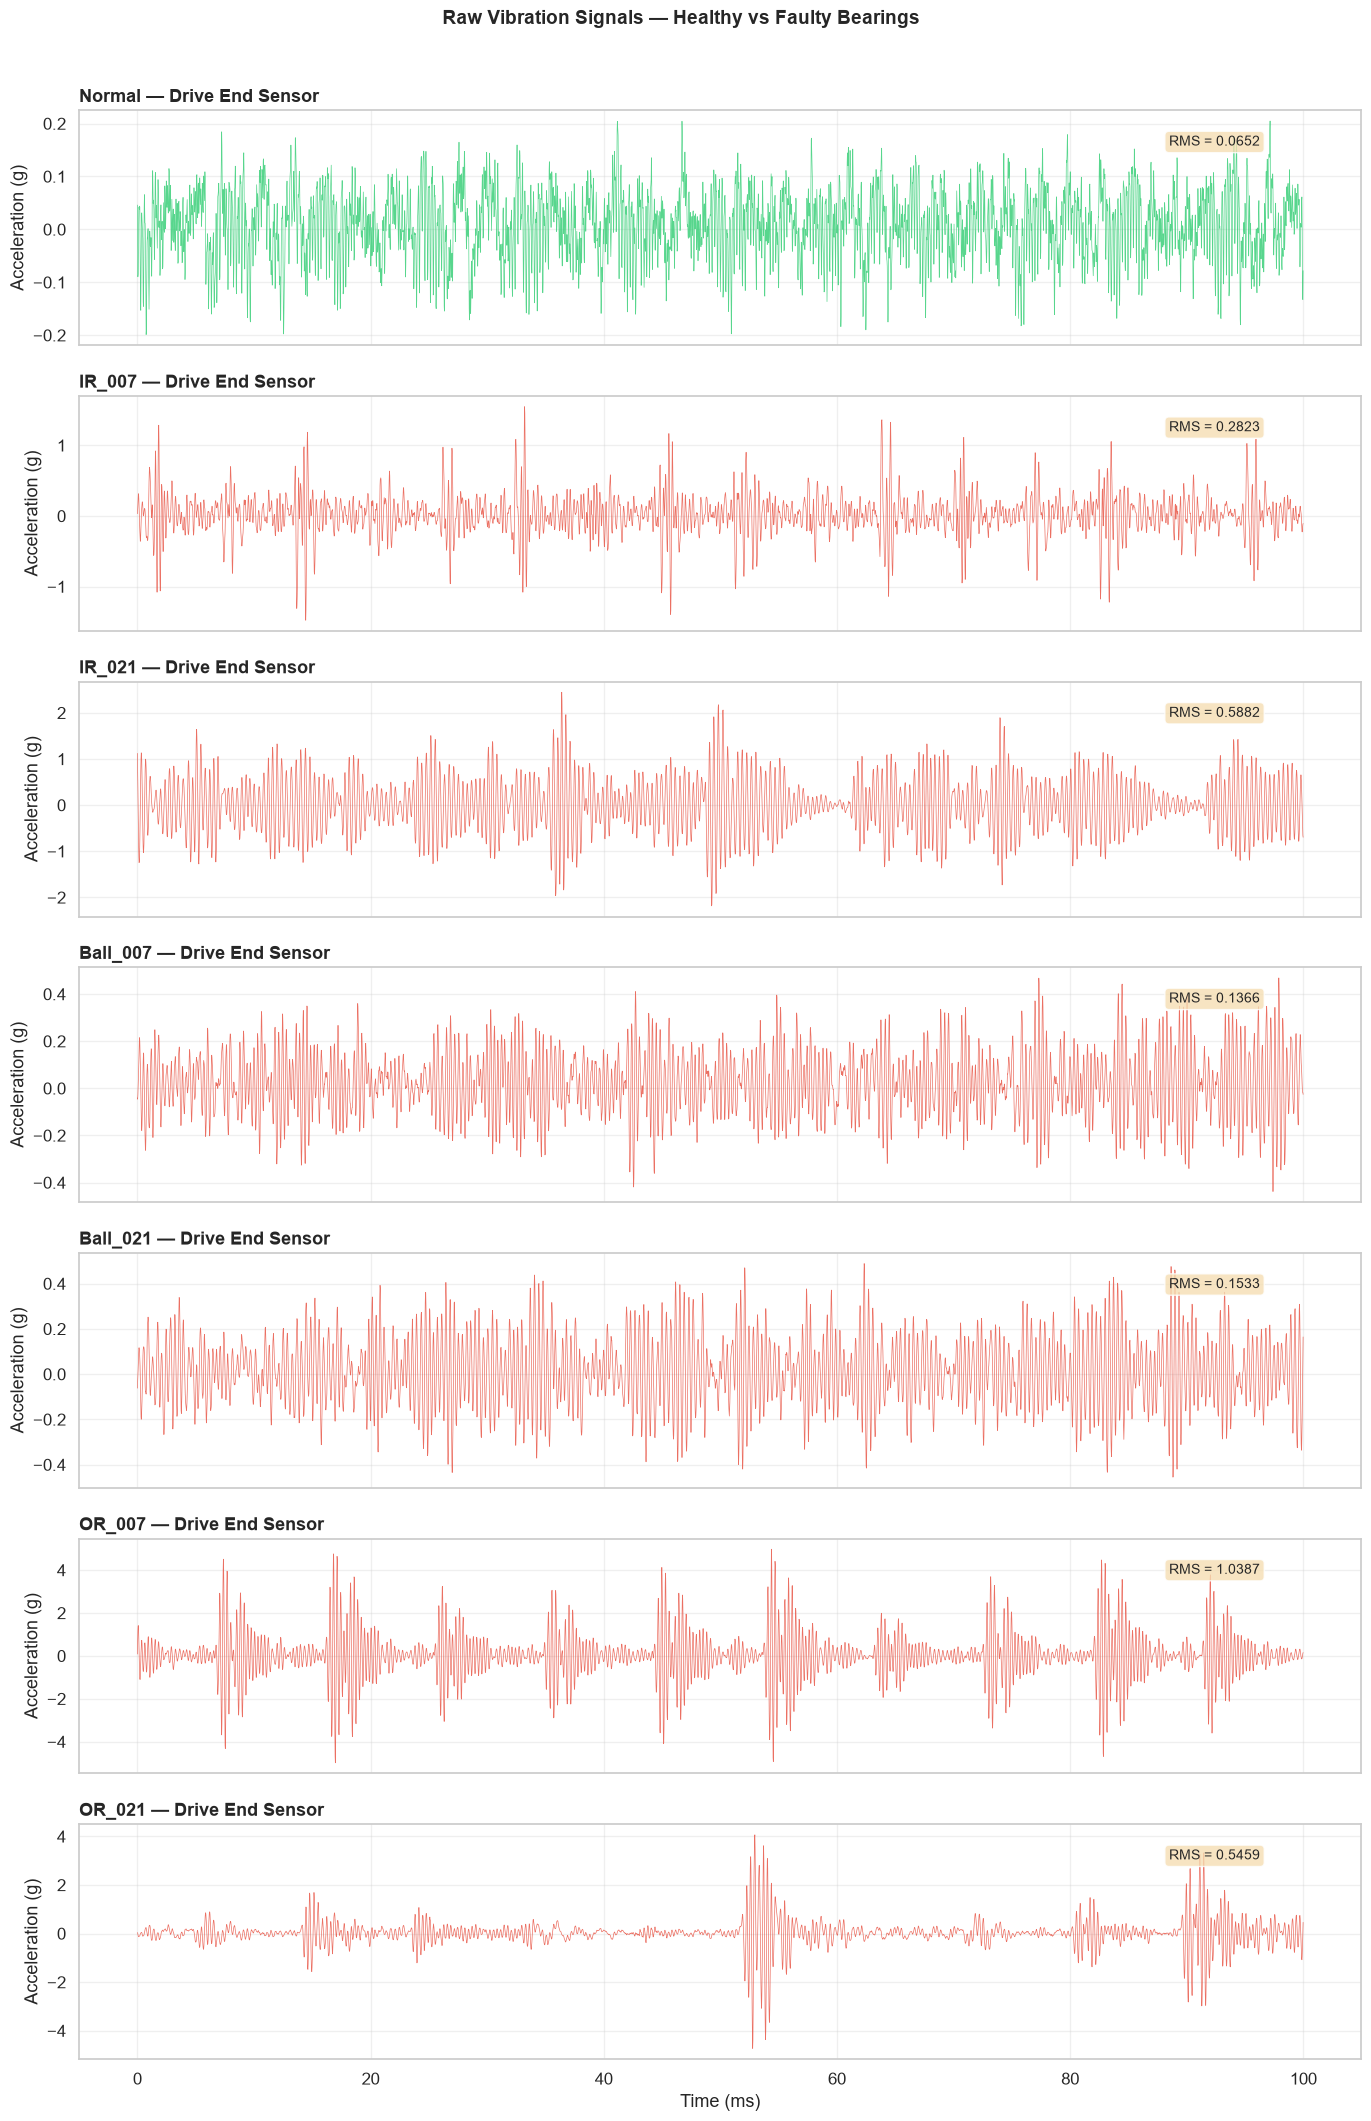


Observations:
- Normal bearing has smooth, low-amplitude vibration
- Faulty bearings show impulse spikes and higher amplitude
- Higher severity (021) shows more extreme spikes than lower (007)
- Different fault types (IR vs OR vs Ball) have different patterns


In [7]:
# ============================================================
# 1.7 Time-Domain Visualization: Raw Vibration Signals
# ============================================================

SAMPLE_RATE = 48000  # 48 kHz
WINDOW_SEC = 0.1     # 100 ms window
WINDOW_SAMPLES = int(SAMPLE_RATE * WINDOW_SEC)

# Select representative fault conditions
plot_labels = ['Normal', 'IR_007', 'IR_021', 'Ball_007', 'Ball_021',
               'OR_007', 'OR_021']

fig, axes = plt.subplots(len(plot_labels), 1, figsize=(14, 3 * len(plot_labels)),
                          sharex=True)

for i, label in enumerate(plot_labels):
    signal = raw_data[label]['de'][:WINDOW_SAMPLES]
    time_axis = np.arange(len(signal)) / SAMPLE_RATE * 1000  # convert to ms

    color = '#2ecc71' if label == 'Normal' else '#e74c3c'
    axes[i].plot(time_axis, signal, linewidth=0.5, color=color, alpha=0.8)
    axes[i].set_ylabel('Acceleration (g)')
    axes[i].set_title(f'{label} — Drive End Sensor', fontweight='bold', loc='left')
    axes[i].grid(True, alpha=0.3)

    # Add RMS annotation
    rms = np.sqrt(np.mean(signal**2))
    axes[i].annotate(f'RMS = {rms:.4f}', xy=(0.85, 0.85),
                     xycoords='axes fraction', fontsize=10,
                     bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

axes[-1].set_xlabel('Time (ms)')
plt.suptitle('Raw Vibration Signals — Healthy vs Faulty Bearings',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("\nObservations:")
print("- Normal bearing has smooth, low-amplitude vibration")
print("- Faulty bearings show impulse spikes and higher amplitude")
print("- Higher severity (021) shows more extreme spikes than lower (007)")
print("- Different fault types (IR vs OR vs Ball) have different patterns")

## 1.8 Statistical Comparison per Fault Class

Beyond visual inspection, we compute key statistics for each fault condition to quantify the differences.

**Key indicators for bearing health:**
- **RMS** — overall vibration energy (higher = worse)
- **Kurtosis** — "peakedness" of the distribution. Healthy bearings have near-Gaussian distributions (kurtosis ≈ 3). Damaged bearings produce sharp impulses that increase kurtosis significantly.
- **Crest Factor** — peak/RMS ratio. High values indicate impulse-type faults.
- **Skewness** — asymmetry. Fault-induced impacts can shift the distribution.

In [8]:
# ============================================================
# 1.8 Statistical Comparison per Fault Class
# ============================================================

def compute_raw_statistics(signal, label):
    """
    Compute time-domain statistics for a raw vibration signal.

    Parameters
    ----------
    signal : np.ndarray
        Raw vibration samples (1D array)
    label : str
        Fault condition label

    Returns
    -------
    dict : Statistical summary
    """
    return {
        'Fault': label,
        'Samples': len(signal),
        'Mean': np.mean(signal),
        'Std': np.std(signal),
        'RMS': np.sqrt(np.mean(signal**2)),
        'Min': np.min(signal),
        'Max': np.max(signal),
        'Peak-to-Peak': np.max(signal) - np.min(signal),
        'Skewness': stats.skew(signal),
        'Kurtosis': stats.kurtosis(signal),  # excess kurtosis (0 for Gaussian)
        'Crest Factor': np.max(np.abs(signal)) / np.sqrt(np.mean(signal**2)),
    }

# Compute for all fault conditions
stats_list = []
for label in sorted(raw_data.keys()):
    s = compute_raw_statistics(raw_data[label]['de'], label)
    stats_list.append(s)

df_stats = pd.DataFrame(stats_list).set_index('Fault')
print("Statistical Summary per Fault Condition (Drive End Sensor):")
print("="*70)
df_stats

Statistical Summary per Fault Condition (Drive End Sensor):


,Samples,Mean,Std,RMS,Min,Max,Peak-to-Peak,Skewness,Kurtosis,Crest Factor
Fault,,,,,,,,,,
Ball_007,487384,0.0190,0.1401,0.1414,-0.6160,0.6755,1.2915,0.0107,0.0722,4.7771
Ball_014,486224,0.0114,0.1475,0.1480,-2.4877,2.5954,5.0831,0.1161,15.0633,17.5384
Ball_021,486804,0.0119,0.2131,0.2134,-2.8211,2.6653,5.4864,0.0051,6.9425,13.2183
IR_007,486224,0.0207,0.2779,0.2787,-1.5742,1.6516,3.2258,-0.0910,4.3687,5.9263
IR_014,489125,0.0312,0.1954,0.1979,-1.2083,1.3637,2.5720,-0.0047,1.3653,6.8918
IR_021,485063,0.0113,0.6084,0.6085,-3.1142,3.4177,6.5320,0.0335,0.9373,5.6169
Normal,483903,0.0126,0.0652,0.0664,-0.3459,0.3175,0.6634,-0.1730,-0.0694,5.2129
OR_007,486804,0.0121,1.0606,1.0607,-5.3636,5.3043,10.6679,0.0725,3.8648,5.0566
OR_014,484483,0.0121,0.1366,0.1371,-1.3479,1.3694,2.7172,-0.0043,0.6782,9.9872


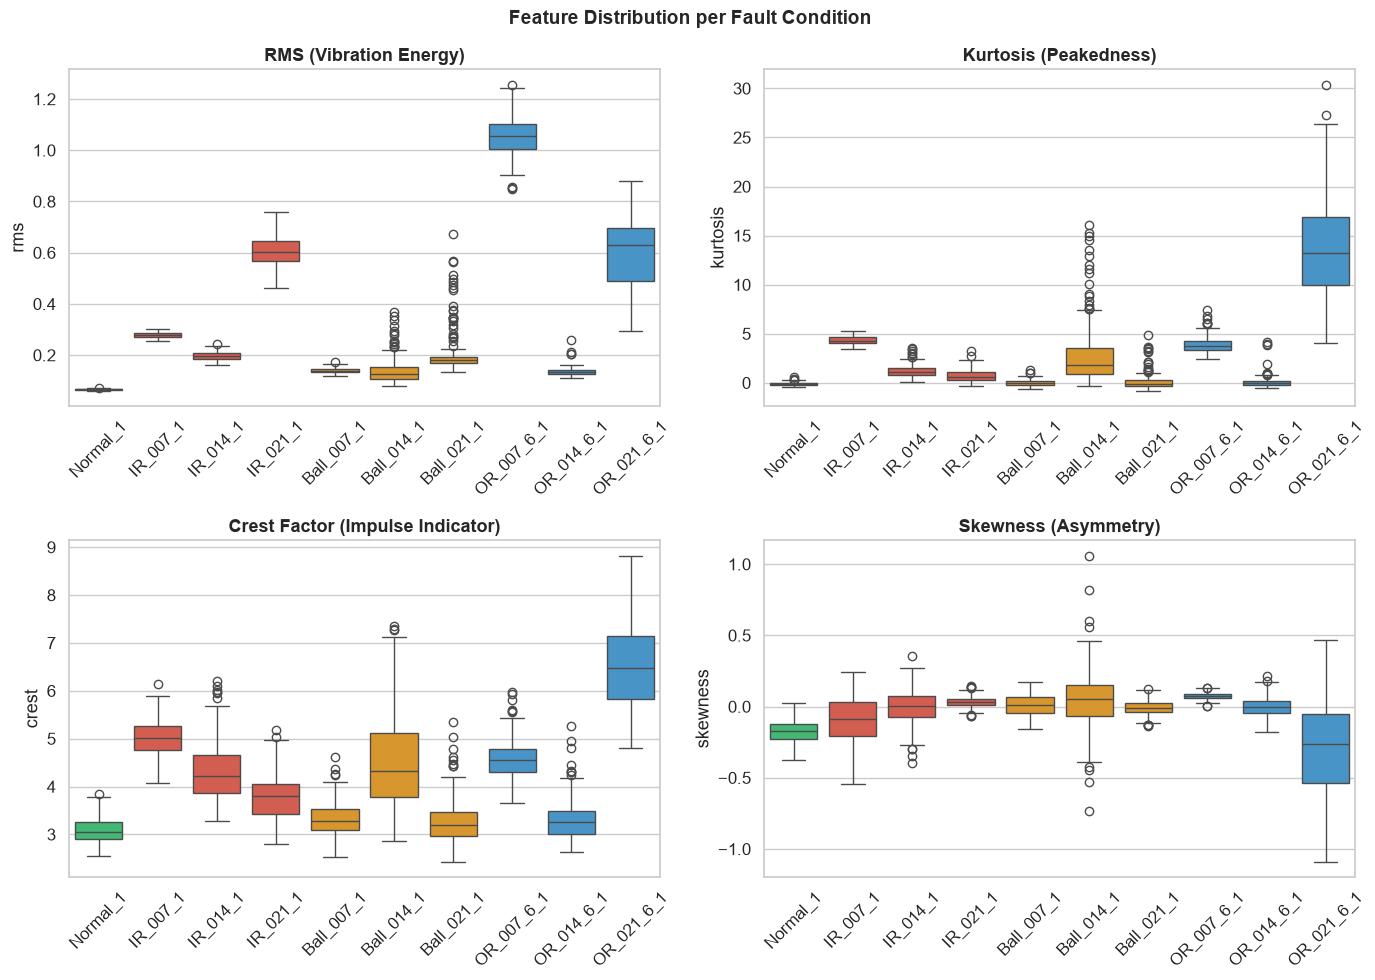


Key observations:
- RMS increases with fault severity (007 < 014 < 021)
- Kurtosis is much higher for Ball faults (impulse-heavy)
- Crest factor distinguishes fault types effectively
- These features will be useful for classification


In [9]:
# ============================================================
# 1.8b Box Plot Comparison of Key Statistics
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features_to_plot = ['rms', 'kurtosis', 'crest', 'skewness']
titles = ['RMS (Vibration Energy)', 'Kurtosis (Peakedness)',
          'Crest Factor (Impulse Indicator)', 'Skewness (Asymmetry)']

for idx, (feat, title) in enumerate(zip(features_to_plot, titles)):
    ax = axes[idx // 2][idx % 2]

    # Order: Normal first, then by fault type
    order = ['Normal_1', 'IR_007_1', 'IR_014_1', 'IR_021_1',
             'Ball_007_1', 'Ball_014_1', 'Ball_021_1',
             'OR_007_6_1', 'OR_014_6_1', 'OR_021_6_1']

    sns.boxplot(data=df_features, x='fault', y=feat, ax=ax, order=order,
                palette=['#2ecc71'] + ['#e74c3c']*3 + ['#f39c12']*3 + ['#3498db']*3)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Feature Distribution per Fault Condition', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nKey observations:")
print("- RMS increases with fault severity (007 < 014 < 021)")
print("- Kurtosis is much higher for Ball faults (impulse-heavy)")
print("- Crest factor distinguishes fault types effectively")
print("- These features will be useful for classification")

## 1.9 Distribution Analysis

We visualize the distribution (histogram + KDE) of each feature to determine:
- **Is it Gaussian?** → Standardization works well
- **Is it skewed?** → May need log transform or Power Transformer (Notebook 2)
- **Are there multiple modes?** → Different fault types may form clusters
- **Are there outliers?** → May need Robust Scaler (Notebook 3)

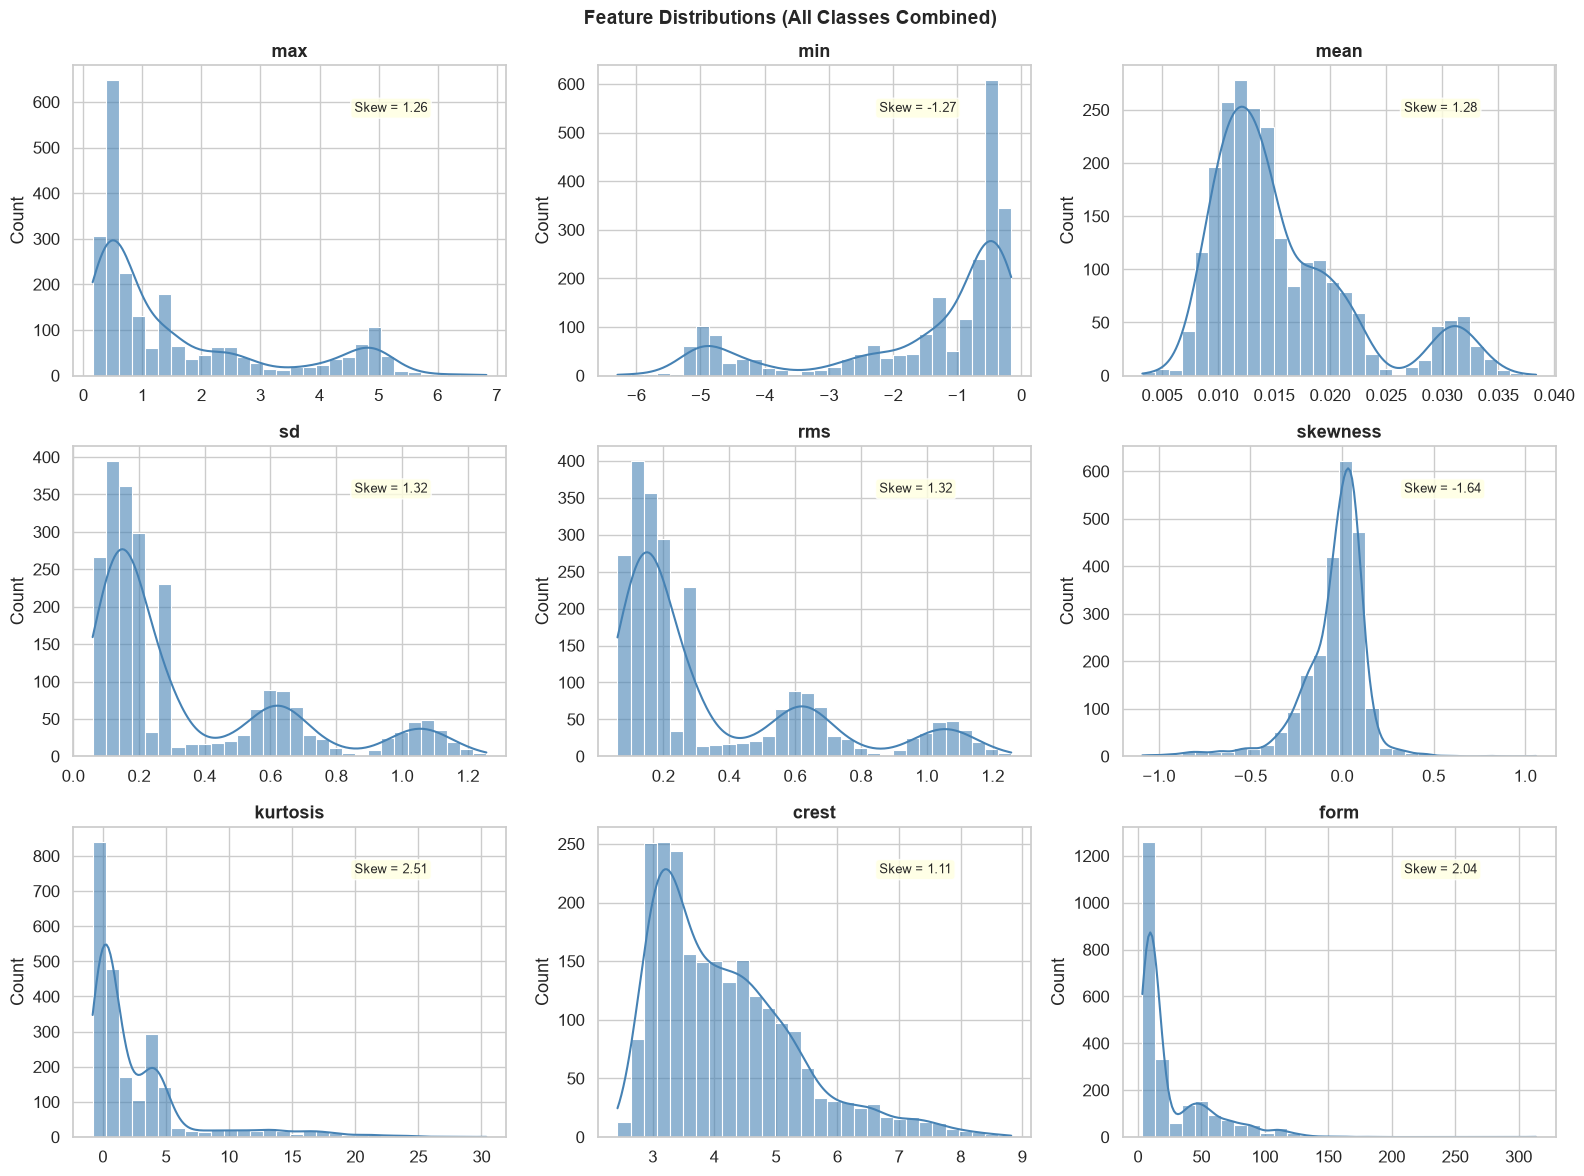


Skewness values:
  max         :   1.264  ⚠️ Skewed
  min         :  -1.275  ⚠️ Skewed
  mean        :   1.275  ⚠️ Skewed
  sd          :   1.316  ⚠️ Skewed
  rms         :   1.317  ⚠️ Skewed
  skewness    :  -1.636  ⚠️ Skewed
  kurtosis    :   2.513  ❌ Highly skewed
  crest       :   1.109  ⚠️ Skewed
  form        :   2.045  ❌ Highly skewed


In [10]:
# ============================================================
# 1.9 Distribution Analysis (Histograms + KDE)
# ============================================================

numerical_cols = ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    ax = axes[idx]

    # Overall distribution
    sns.histplot(df_features[col], kde=True, ax=ax, color='steelblue',
                 bins=30, alpha=0.6, edgecolor='white')

    # Add skewness annotation
    skew_val = df_features[col].skew()
    ax.annotate(f'Skew = {skew_val:.2f}', xy=(0.65, 0.85),
                xycoords='axes fraction', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

    ax.set_title(f'{col}', fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Feature Distributions (All Classes Combined)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nSkewness values:")
for col in numerical_cols:
    skew = df_features[col].skew()
    status = '\u2705 OK' if abs(skew) < 1 else '\u26a0\ufe0f Skewed' if abs(skew) < 2 else '\u274c Highly skewed'
    print(f"  {col:12s}: {skew:7.3f}  {status}")

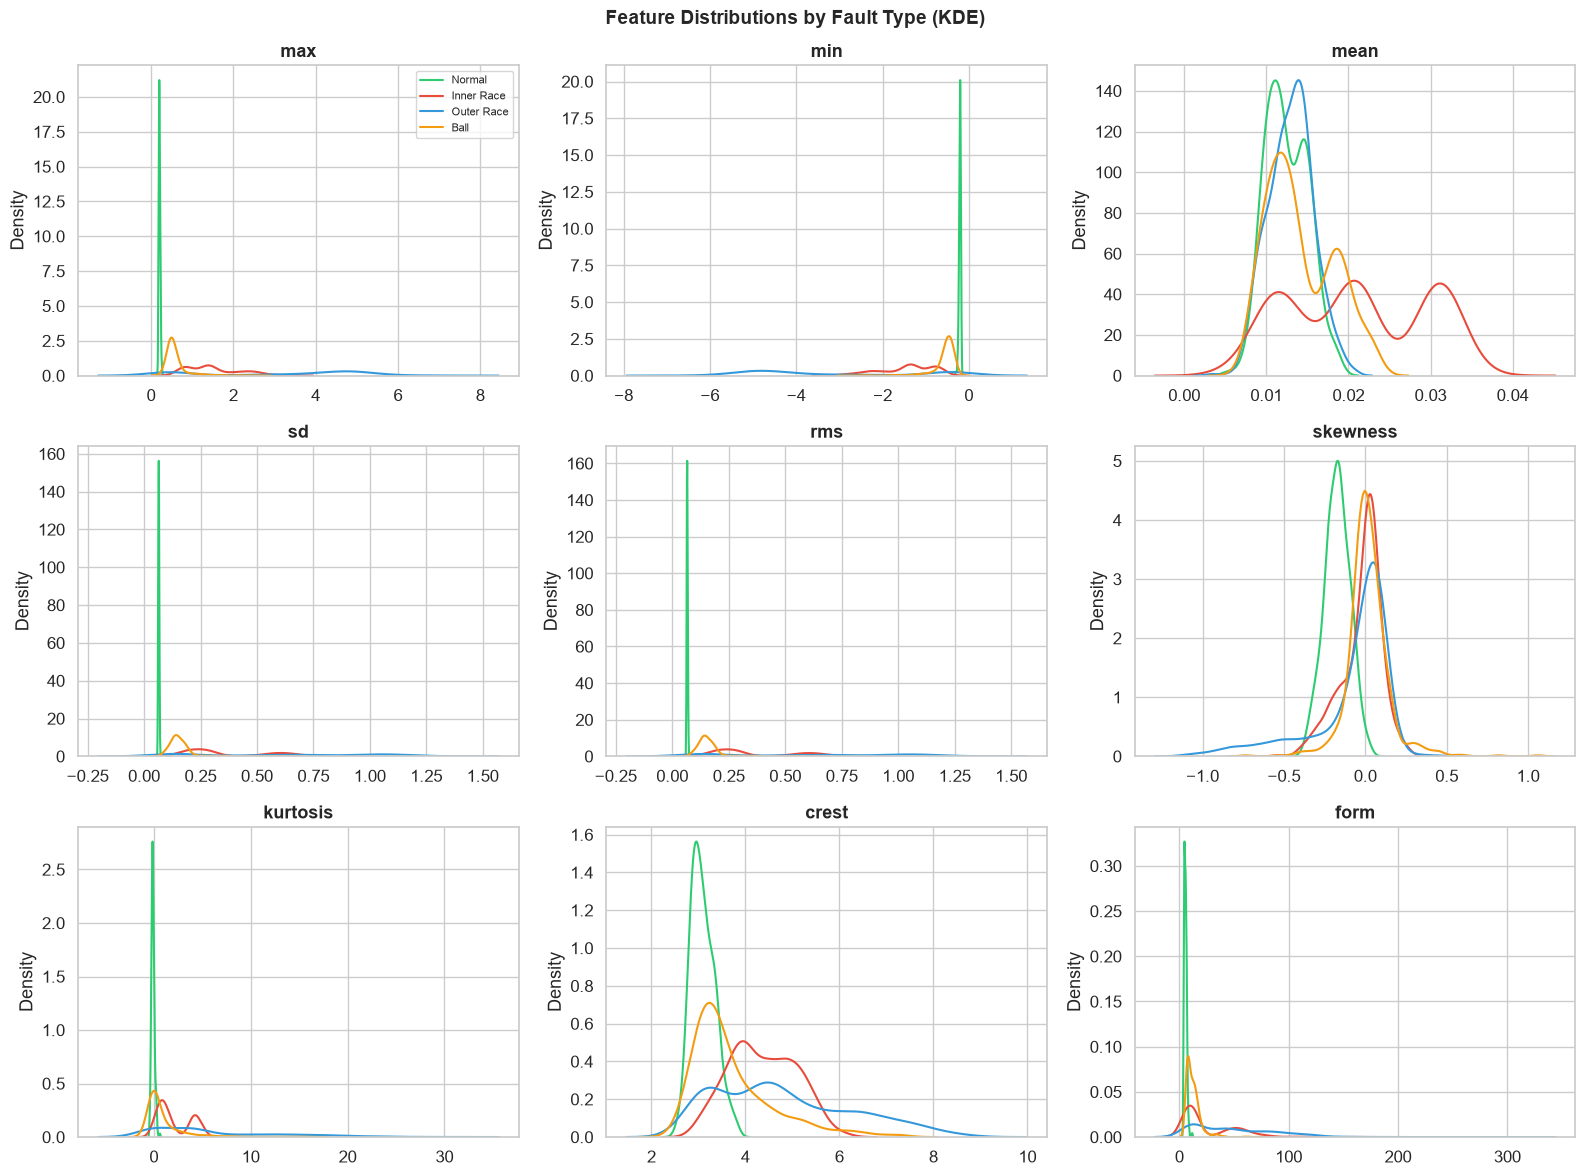


Key observations:
- 'rms' and 'sd' show clear separation between Normal and faulty
- 'kurtosis' has the most distinct distributions per fault type
- 'mean' distributions overlap heavily — less discriminative
- Some features are skewed — will need transformation in Notebook 2


In [11]:
# ============================================================
# 1.9b Distribution per Fault Type (Colored KDE)
# ============================================================

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

colors = {'Normal': '#2ecc71', 'Inner Race': '#e74c3c',
          'Outer Race': '#3498db', 'Ball': '#f39c12'}

for idx, col in enumerate(numerical_cols):
    ax = axes[idx]
    for fault_type, color in colors.items():
        subset = df_features[df_features['fault_type'] == fault_type][col]
        sns.kdeplot(subset, ax=ax, label=fault_type, color=color, linewidth=1.5)
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('')
    if idx == 0:
        ax.legend(fontsize=8)

plt.suptitle('Feature Distributions by Fault Type (KDE)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nKey observations:")
print("- 'rms' and 'sd' show clear separation between Normal and faulty")
print("- 'kurtosis' has the most distinct distributions per fault type")
print("- 'mean' distributions overlap heavily \u2014 less discriminative")
print("- Some features are skewed \u2014 will need transformation in Notebook 2")

## 1.10 Outlier Detection

Outliers in vibration data are interesting because they could be:
- **Real fault impulses** — genuine signals we want to detect
- **Sensor noise or artifacts** — errors we want to remove

We use the **IQR method** (same as Week 4 EDA) to identify statistical outliers, then examine whether they correlate with fault conditions.

In [12]:
# ============================================================
# 1.10 Outlier Detection (IQR Method)
# ============================================================

def count_outliers_iqr(series, factor=1.5):
    """
    Count outliers using the IQR method.

    Parameters
    ----------
    series : pd.Series
        Numerical column to check
    factor : float
        IQR multiplier (1.5 = standard, 3.0 = extreme)

    Returns
    -------
    int : Number of outliers detected
    """
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    return ((series < lower) | (series > upper)).sum()

print("Outlier counts per feature (IQR method, factor=1.5):")
print("=" * 50)
outlier_data = []
for col in numerical_cols:
    n_outliers = count_outliers_iqr(df_features[col])
    pct = n_outliers / len(df_features) * 100
    outlier_data.append({'Feature': col, 'Outliers': n_outliers, 'Percent': f'{pct:.1f}%'})
    print(f"  {col:12s}: {n_outliers:4d} outliers ({pct:.1f}%)")

# Are outliers concentrated in faulty classes?
print("\n\nOutlier distribution by fault type (rms feature):")
print("=" * 50)
Q1 = df_features['rms'].quantile(0.25)
Q3 = df_features['rms'].quantile(0.75)
IQR = Q3 - Q1
is_outlier = (df_features['rms'] < Q1 - 1.5*IQR) | (df_features['rms'] > Q3 + 1.5*IQR)
if is_outlier.sum() > 0:
    print(df_features[is_outlier]['fault_type'].value_counts())
else:
    print("No outliers detected in RMS.")

print("\n\u2139\ufe0f In bearing fault data, outliers often ARE the signal, not noise.")
print("We will use RobustScaler (Notebook 3) to handle this gracefully.")

Outlier counts per feature (IQR method, factor=1.5):
  max         :   84 outliers (3.7%)
  min         :  214 outliers (9.3%)
  mean        :  182 outliers (7.9%)
  sd          :   11 outliers (0.5%)
  rms         :   11 outliers (0.5%)
  skewness    :  139 outliers (6.0%)
  kurtosis    :  186 outliers (8.1%)
  crest       :   60 outliers (2.6%)
  form        :  122 outliers (5.3%)


Outlier distribution by fault type (rms feature):
fault_type
Outer Race    11
Name: count, dtype: int64

ℹ️ In bearing fault data, outliers often ARE the signal, not noise.
We will use RobustScaler (Notebook 3) to handle this gracefully.


## 1.11 Correlation Analysis

Correlation tells us which features move together. If two features are highly correlated (|r| > 0.95), they carry redundant information and one can be removed during feature selection (Notebook 3).

We compute the **Pearson correlation matrix** and visualize it as a heatmap.

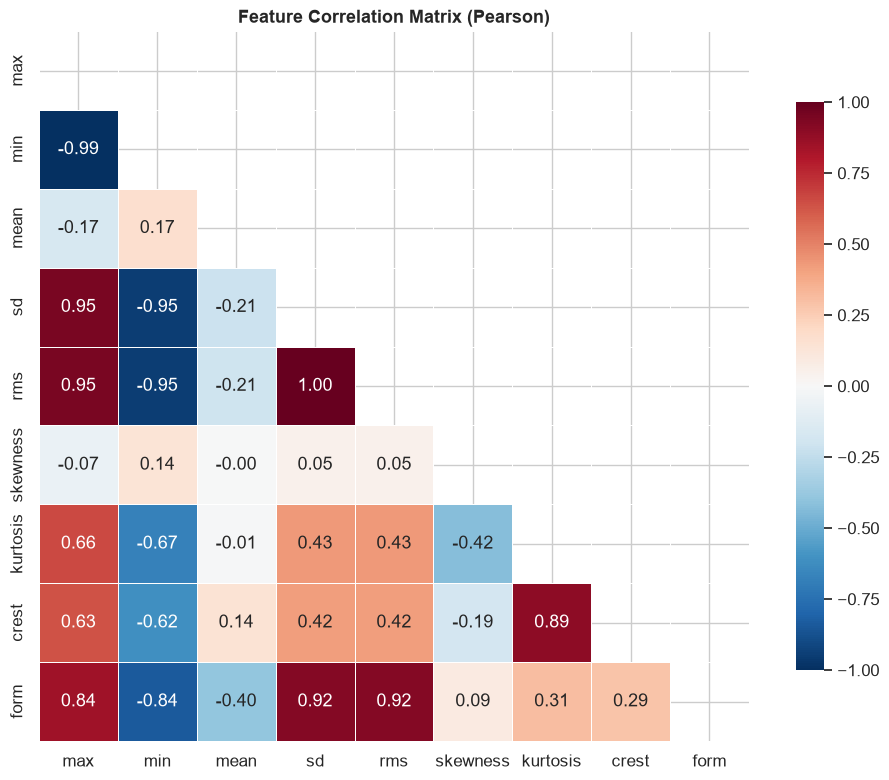


Highly correlated feature pairs (|r| > 0.90):
  max          <-> min           r = -0.993
  max          <-> sd            r = 0.952
  max          <-> rms           r = 0.952
  min          <-> sd            r = -0.947
  min          <-> rms           r = -0.947
  sd           <-> rms           r = 1.000
  sd           <-> form          r = 0.921
  rms          <-> form          r = 0.920

ℹ️ Highly correlated features are candidates for removal in Notebook 3.
Keeping both wastes compute and can hurt some models.


In [13]:
# ============================================================
# 1.11 Correlation Analysis
# ============================================================

corr_matrix = df_features[numerical_cols].corr()

# Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # upper triangle mask
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            mask=mask, ax=ax, square=True, linewidths=0.5,
            vmin=-1, vmax=1, cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Matrix (Pearson)', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

# Find highly correlated pairs
print("\nHighly correlated feature pairs (|r| > 0.90):")
print("=" * 50)
for i in range(len(numerical_cols)):
    for j in range(i+1, len(numerical_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.90:
            print(f"  {numerical_cols[i]:12s} <-> {numerical_cols[j]:12s}  r = {r:.3f}")

print("\n\u2139\ufe0f Highly correlated features are candidates for removal in Notebook 3.")
print("Keeping both wastes compute and can hurt some models.")

## 1.12 Frequency Domain Preview (FFT)

### Why look at frequencies?

A damaged bearing surface produces periodic **impulse responses** every time a rolling element hits the defect. These impulses repeat at characteristic frequencies determined by the bearing geometry:

| Fault Location | Characteristic Frequency | Abbreviation |
|---------------|-------------------------|---------------|
| Inner Race | Ball Pass Frequency Inner | **BPFI** |
| Outer Race | Ball Pass Frequency Outer | **BPFO** |
| Ball | Ball Spin Frequency | **BSF** |

The **Fast Fourier Transform (FFT)** converts a time-domain signal into its frequency components, revealing these fault-characteristic peaks.

**This is the core motivation for VectoGuard's frequency-based approach** — and why Sliding-DFT (Notebook 5) and GRU+Attention (Notebook 6) focus on frequency features.

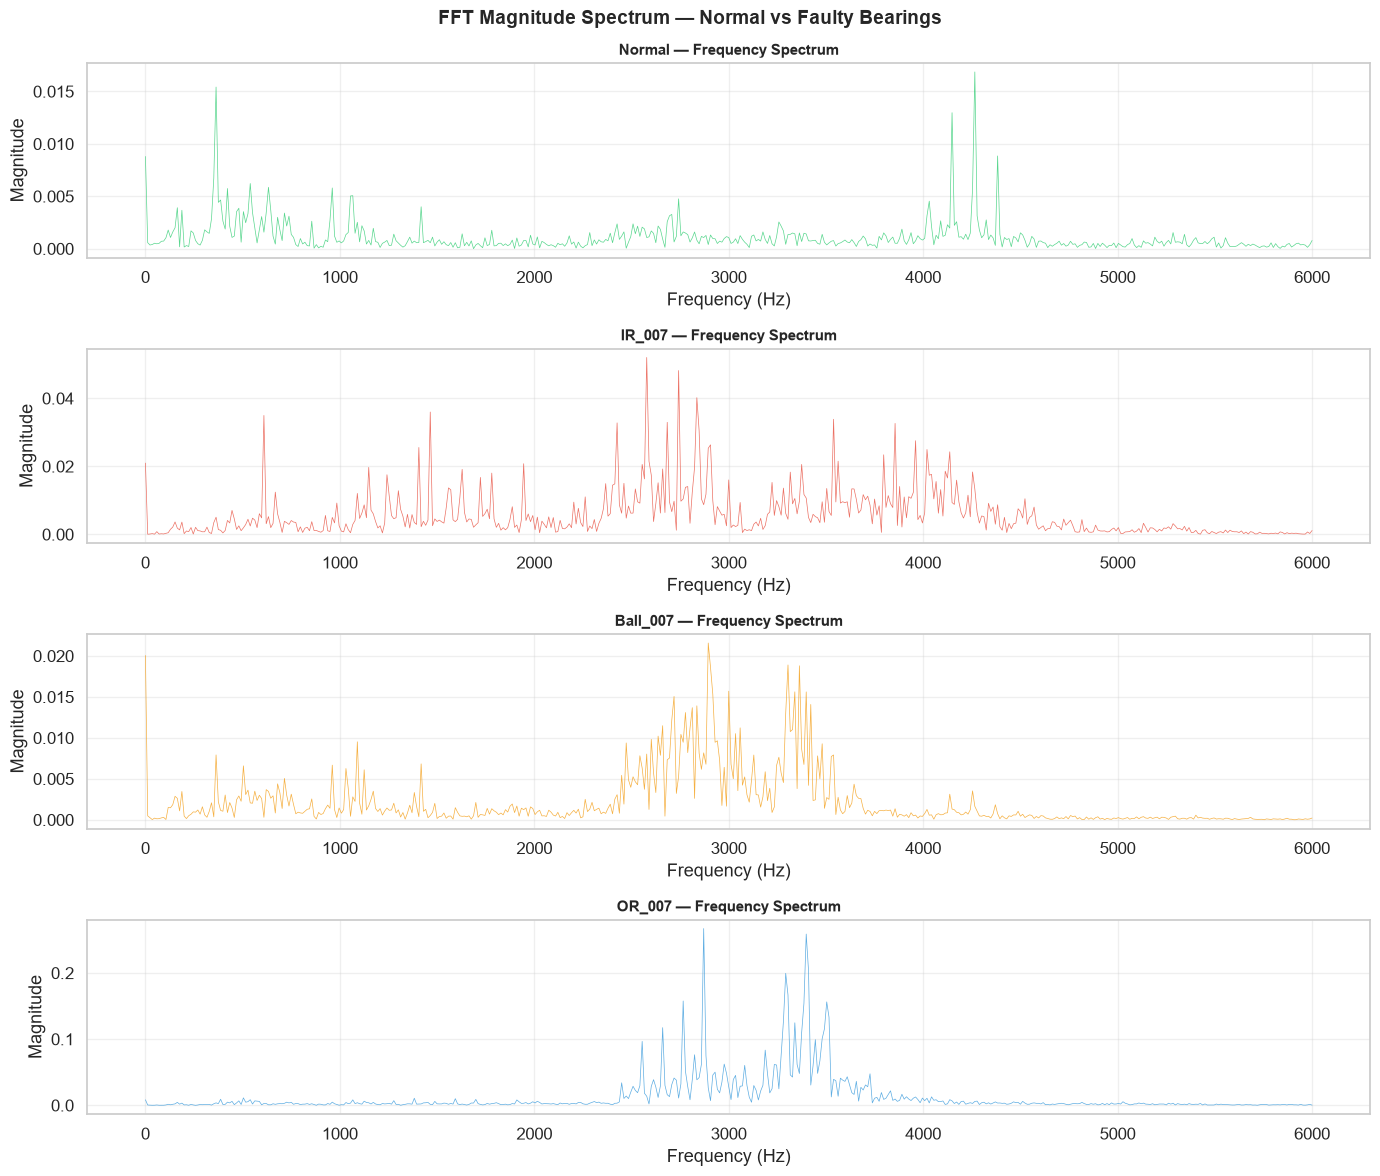


Key observations:
- Normal: energy concentrated in low frequencies, smooth spectrum
- Inner Race: distinct peaks at fault characteristic frequencies
- Ball: broader spectral changes with some characteristic peaks
- Outer Race: clear periodic peaks at BPFO harmonics

➡️ This confirms that frequency-domain features are ESSENTIAL
   for bearing fault detection — motivating our Sliding-DFT approach.


In [14]:
# ============================================================
# 1.12 Frequency Domain Preview (FFT)
# ============================================================

def plot_fft(signal, sample_rate, title, ax, color='steelblue', max_freq=6000):
    """
    Compute and plot the FFT magnitude spectrum of a signal.

    Parameters
    ----------
    signal : np.ndarray
        Time-domain vibration signal
    sample_rate : int
        Sampling rate in Hz
    title : str
        Plot title
    ax : matplotlib.axes.Axes
        Axes to plot on
    color : str
        Line color
    max_freq : float
        Maximum frequency to display (Hz)
    """
    N = len(signal)
    yf = np.abs(fft(signal))[:N // 2]  # single-sided FFT
    xf = fftfreq(N, 1 / sample_rate)[:N // 2]  # frequency axis

    # Normalize magnitude
    yf = yf / N

    # Limit to max_freq
    mask = xf <= max_freq
    ax.plot(xf[mask], yf[mask], linewidth=0.5, color=color, alpha=0.8)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Magnitude')
    ax.grid(True, alpha=0.3)

# Compare Normal vs each fault type (small severity 007)
compare_labels = ['Normal', 'IR_007', 'Ball_007', 'OR_007']
compare_colors = ['#2ecc71', '#e74c3c', '#f39c12', '#3498db']

fig, axes = plt.subplots(4, 1, figsize=(14, 12))

for i, (label, color) in enumerate(zip(compare_labels, compare_colors)):
    # Use a 4096-sample window for good frequency resolution
    window = raw_data[label]['de'][:4096]
    plot_fft(window, SAMPLE_RATE, f'{label} — Frequency Spectrum', axes[i], color)

plt.suptitle('FFT Magnitude Spectrum — Normal vs Faulty Bearings',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nKey observations:")
print("- Normal: energy concentrated in low frequencies, smooth spectrum")
print("- Inner Race: distinct peaks at fault characteristic frequencies")
print("- Ball: broader spectral changes with some characteristic peaks")
print("- Outer Race: clear periodic peaks at BPFO harmonics")
print("\n\u27a1\ufe0f This confirms that frequency-domain features are ESSENTIAL")
print("   for bearing fault detection \u2014 motivating our Sliding-DFT approach.")

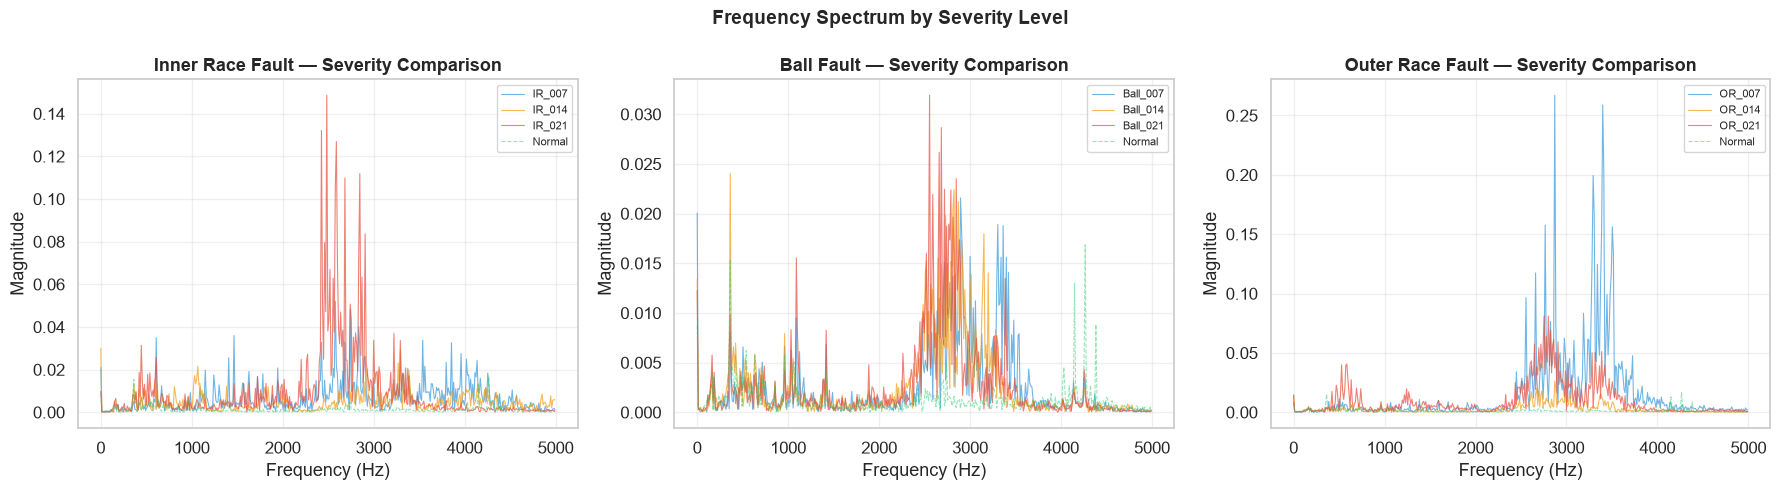


Higher severity (021) shows larger magnitude at fault frequencies.
This is the signal that our GRU + Attention model will learn to detect.


In [15]:
# ============================================================
# 1.12b FFT Overlay: All severities for one fault type
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

fault_groups = {
    'Inner Race': ['IR_007', 'IR_014', 'IR_021'],
    'Ball': ['Ball_007', 'Ball_014', 'Ball_021'],
    'Outer Race': ['OR_007', 'OR_014', 'OR_021'],
}
severity_colors = ['#3498db', '#f39c12', '#e74c3c']  # mild, medium, severe

for ax_idx, (group_name, labels) in enumerate(fault_groups.items()):
    ax = axes[ax_idx]
    for label, color in zip(labels, severity_colors):
        window = raw_data[label]['de'][:4096]
        N = len(window)
        yf = np.abs(fft(window))[:N // 2] / N
        xf = fftfreq(N, 1 / SAMPLE_RATE)[:N // 2]
        mask = xf <= 5000
        ax.plot(xf[mask], yf[mask], linewidth=0.8, color=color,
                alpha=0.7, label=label)

    # Add Normal reference
    window = raw_data['Normal']['de'][:4096]
    N = len(window)
    yf = np.abs(fft(window))[:N // 2] / N
    xf = fftfreq(N, 1 / SAMPLE_RATE)[:N // 2]
    mask = xf <= 5000
    ax.plot(xf[mask], yf[mask], linewidth=0.8, color='#2ecc71',
            alpha=0.5, label='Normal', linestyle='--')

    ax.set_title(f'{group_name} Fault — Severity Comparison', fontweight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Magnitude')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Frequency Spectrum by Severity Level', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nHigher severity (021) shows larger magnitude at fault frequencies.")
print("This is the signal that our GRU + Attention model will learn to detect.")

## 1.13 Synthetic Cloud Metrics (Digital Domain)

VectoGuard monitors **two domains**. For the cloud/digital domain, we generate realistic synthetic server metrics since the Alibaba dataset will be loaded in a later phase.

### What do cloud metrics look like?

A server emits periodic health readings:
- **CPU %** — processor usage (0–100%)
- **Memory %** — RAM usage (0–100%)
- **Latency (ms)** — response time for requests
- **Error Rate** — fraction of failed requests
- **Request Count** — number of requests per interval
- **Queue Depth** — pending requests waiting to be processed

We generate a normal operation period, then inject anomalous behavior (cascading failure pattern) to create labeled data.

In [18]:
# ============================================================
# 1.13 Generate Synthetic Cloud Metrics
# ============================================================

def generate_cloud_metrics(n_normal=1000, n_anomaly=200, seed=42):
    """
    Generate synthetic cloud server metrics with normal and anomalous periods.

    Parameters
    ----------
    n_normal : int
        Number of normal time steps
    n_anomaly : int
        Number of anomalous time steps
    seed : int
        Random seed for reproducibility

    Returns
    -------
    pd.DataFrame : Cloud metrics with 'is_anomaly' label

    Why synthetic?
    The Alibaba Microservice Traces dataset will be loaded in Phase 5.
    For EDA purposes, synthetic data lets us explore what cloud metrics
    look like and practice the same EDA techniques on a different domain.
    """
    rng = np.random.default_rng(seed)

    # Normal operation
    normal = {
        'cpu_percent':    rng.normal(45, 8, n_normal).clip(5, 95),
        'memory_percent': rng.normal(55, 5, n_normal).clip(10, 95),
        'latency_ms':     rng.exponential(15, n_normal) + 5,  # right-skewed
        'error_rate':     rng.exponential(0.005, n_normal).clip(0, 0.1),
        'request_count':  rng.poisson(500, n_normal),
        'queue_depth':    rng.poisson(10, n_normal),
    }

    # Anomalous period (cascading failure)
    t = np.linspace(0, 1, n_anomaly)
    anomaly = {
        'cpu_percent':    45 + 45 * t + rng.normal(0, 3, n_anomaly),  # ramps up
        'memory_percent': 55 + 35 * t**2 + rng.normal(0, 2, n_anomaly),  # quadratic
        'latency_ms':     20 * np.exp(3 * t) + rng.normal(0, 5, n_anomaly),  # exponential
        'error_rate':     0.005 + 0.3 * t**2 + rng.normal(0, 0.01, n_anomaly),  # increasing
        'request_count':  500 - 300 * t + rng.normal(0, 20, n_anomaly),  # dropping
        'queue_depth':    10 + 200 * t**1.5 + rng.normal(0, 5, n_anomaly),  # filling up
    }

    # Combine
    df_normal = pd.DataFrame(normal)
    df_normal['is_anomaly'] = 0
    df_normal['time_step'] = range(n_normal)

    df_anomaly = pd.DataFrame(anomaly)
    df_anomaly['is_anomaly'] = 1
    df_anomaly['time_step'] = range(n_normal, n_normal + n_anomaly)

    df = pd.concat([df_normal, df_anomaly], ignore_index=True)

    # Clip to realistic ranges
    df['cpu_percent'] = df['cpu_percent'].clip(0, 100)
    df['memory_percent'] = df['memory_percent'].clip(0, 100)
    df['latency_ms'] = df['latency_ms'].clip(1, None)
    df['error_rate'] = df['error_rate'].clip(0, 1)
    df['request_count'] = df['request_count'].clip(0, None).astype(int)
    df['queue_depth'] = df['queue_depth'].clip(0, None).astype(int)

    return df

df_cloud = generate_cloud_metrics()
print(f"Cloud metrics shape: {df_cloud.shape}")
print(f"Normal samples: {(df_cloud['is_anomaly'] == 0).sum()}")
print(f"Anomaly samples: {(df_cloud['is_anomaly'] == 1).sum()}")
print(f"\nFirst 5 rows:")
df_cloud.head()

Cloud metrics shape: (1200, 8)
Normal samples: 1000
Anomaly samples: 200

First 5 rows:


,cpu_percent,memory_percent,latency_ms,error_rate,request_count,queue_depth,is_anomaly,time_step
0,47.4377,54.7036,5.4656,0.0041,488,10,0,0
1,36.6801,51.3536,9.6676,0.0019,532,6,0,1
2,51.0036,52.9276,13.5828,0.0007,501,7,0,2
3,52.5245,58.1696,11.6560,0.0015,516,18,0,3
4,29.3917,55.0150,12.9302,0.0016,495,11,0,4


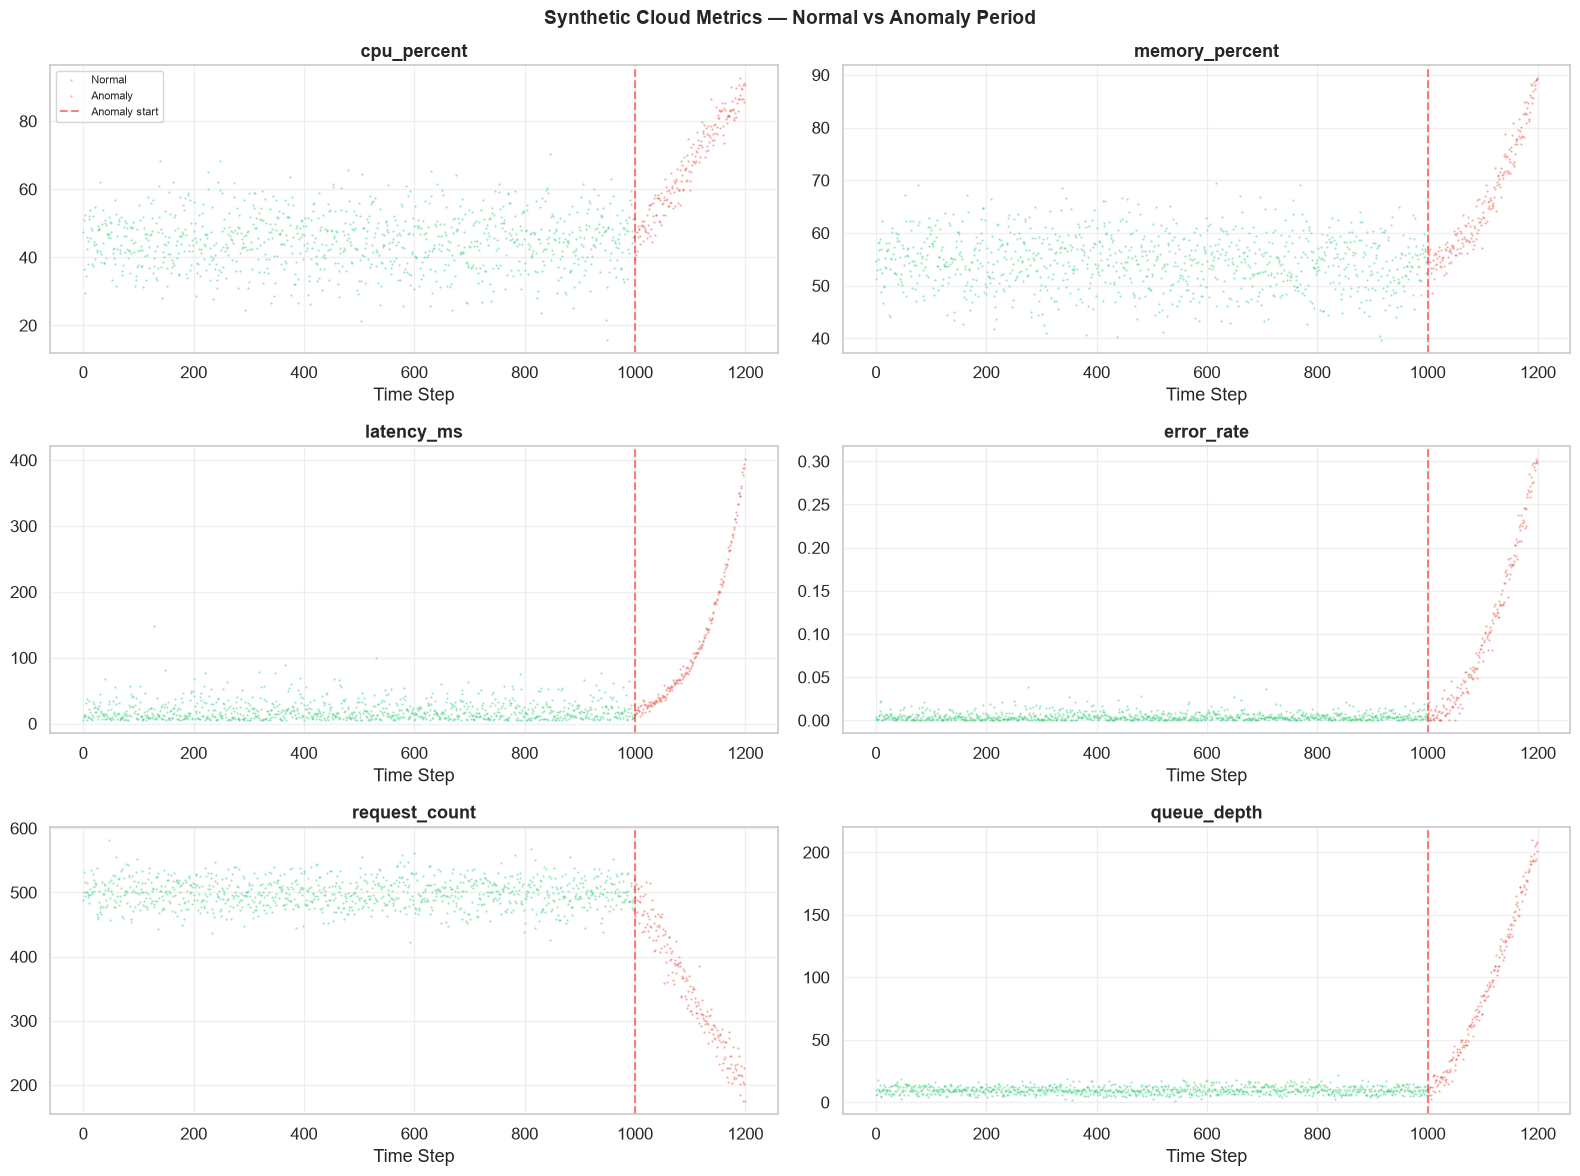


Cloud metric observations:
- CPU and memory ramp up during anomaly (resource exhaustion)
- Latency increases exponentially (cascading delays)
- Error rate climbs (requests failing)
- Request count drops (clients timing out)
- Queue depth spikes (backpressure building)

This is a classic cascading failure pattern.


In [19]:
# ============================================================
# 1.13b Cloud Metrics EDA
# ============================================================

cloud_metrics = ['cpu_percent', 'memory_percent', 'latency_ms',
                 'error_rate', 'request_count', 'queue_depth']

# Time series plots
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(cloud_metrics):
    ax = axes[idx]

    # Color by anomaly
    normal = df_cloud[df_cloud['is_anomaly'] == 0]
    anomaly = df_cloud[df_cloud['is_anomaly'] == 1]

    ax.plot(normal['time_step'], normal[col], '.', markersize=1,
            color='#2ecc71', alpha=0.5, label='Normal')
    ax.plot(anomaly['time_step'], anomaly[col], '.', markersize=1,
            color='#e74c3c', alpha=0.5, label='Anomaly')

    ax.axvline(x=1000, color='red', linestyle='--', alpha=0.5, label='Anomaly start')
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('Time Step')
    ax.grid(True, alpha=0.3)
    if idx == 0:
        ax.legend(fontsize=8)

plt.suptitle('Synthetic Cloud Metrics — Normal vs Anomaly Period',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nCloud metric observations:")
print("- CPU and memory ramp up during anomaly (resource exhaustion)")
print("- Latency increases exponentially (cascading delays)")
print("- Error rate climbs (requests failing)")
print("- Request count drops (clients timing out)")
print("- Queue depth spikes (backpressure building)")
print("\nThis is a classic cascading failure pattern.")

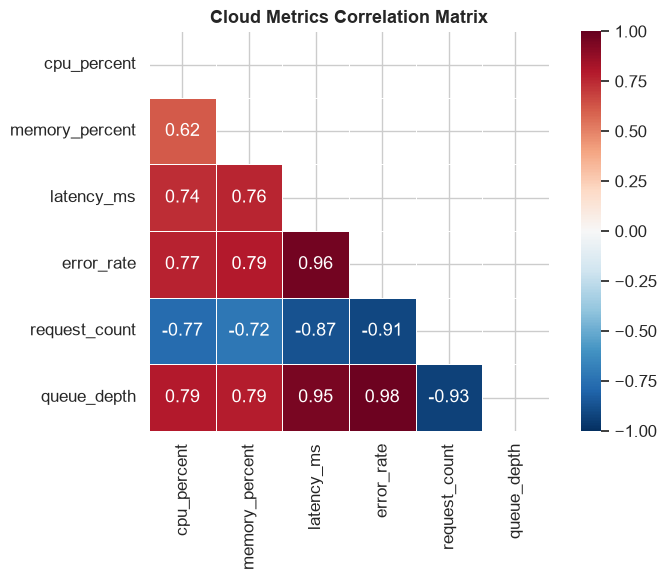


Cloud metric correlations:
- cpu_percent and memory_percent are positively correlated
- latency_ms and queue_depth are strongly correlated (more queue = more delay)
- request_count is negatively correlated with latency (fewer successful requests)

➡️ These correlations are what the Wavelet Transformer will learn to detect.


In [20]:
# ============================================================
# 1.13c Cloud Metrics Correlation Heatmap
# ============================================================

cloud_corr = df_cloud[cloud_metrics].corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(cloud_corr, dtype=bool))
sns.heatmap(cloud_corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            mask=mask, ax=ax, square=True, linewidths=0.5,
            vmin=-1, vmax=1)
ax.set_title('Cloud Metrics Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

print("\nCloud metric correlations:")
print("- cpu_percent and memory_percent are positively correlated")
print("- latency_ms and queue_depth are strongly correlated (more queue = more delay)")
print("- request_count is negatively correlated with latency (fewer successful requests)")
print("\n\u27a1\ufe0f These correlations are what the Wavelet Transformer will learn to detect.")

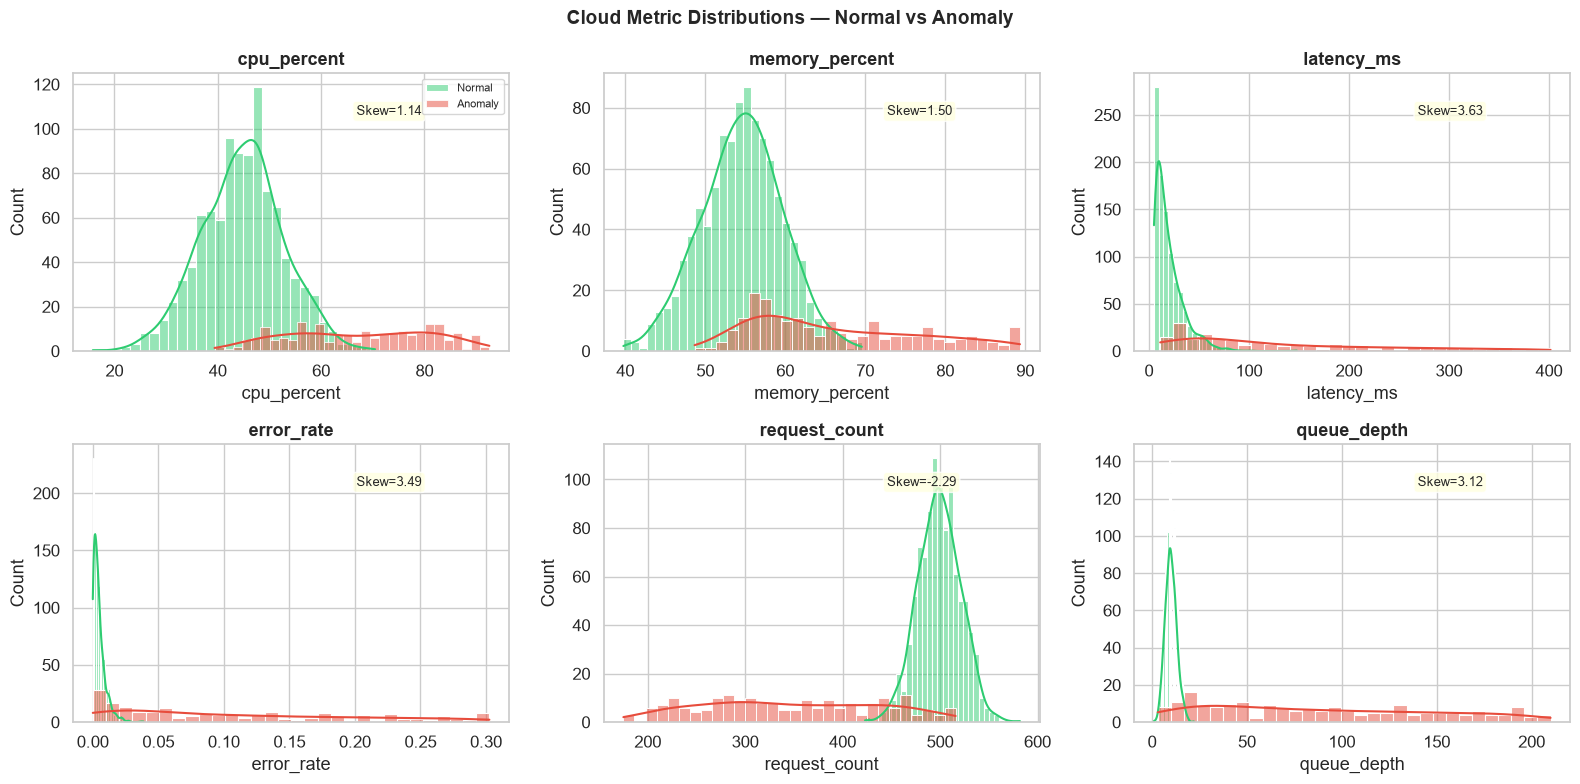


Cloud distribution observations:
- latency_ms is heavily right-skewed — needs log transform (Notebook 2)
- request_count follows Poisson — roughly symmetric
- error_rate is right-skewed — most values near zero
- Normal and Anomaly distributions are clearly separable


In [21]:
# ============================================================
# 1.13d Cloud Metrics Distributions
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for idx, col in enumerate(cloud_metrics):
    ax = axes[idx]
    sns.histplot(df_cloud[df_cloud['is_anomaly'] == 0][col], kde=True,
                 ax=ax, color='#2ecc71', alpha=0.5, label='Normal', bins=30)
    sns.histplot(df_cloud[df_cloud['is_anomaly'] == 1][col], kde=True,
                 ax=ax, color='#e74c3c', alpha=0.5, label='Anomaly', bins=30)

    skew_val = df_cloud[col].skew()
    ax.annotate(f'Skew={skew_val:.2f}', xy=(0.65, 0.85),
                xycoords='axes fraction', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    ax.set_title(col, fontweight='bold')
    if idx == 0:
        ax.legend(fontsize=8)

plt.suptitle('Cloud Metric Distributions — Normal vs Anomaly',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nCloud distribution observations:")
print("- latency_ms is heavily right-skewed \u2014 needs log transform (Notebook 2)")
print("- request_count follows Poisson \u2014 roughly symmetric")
print("- error_rate is right-skewed \u2014 most values near zero")
print("- Normal and Anomaly distributions are clearly separable")

## 1.14 Load Pre-Windowed NPZ Data

The dataset also includes a pre-processed `.npz` file with 4,600 samples already windowed into 32×32 arrays (1,024 samples per window, reshaped). This format is useful for CNN-style models, and we briefly inspect its structure for future reference.

NPZ Data shape: (4600, 32, 32)  (samples x height x width)
NPZ Labels shape: (4600,)

Label distribution:
  Ball_007  : 460 samples
  Ball_014  : 460 samples
  Ball_021  : 460 samples
  IR_007    : 460 samples
  IR_014    : 460 samples
  IR_021    : 460 samples
  Normal    : 460 samples
  OR_007    : 460 samples
  OR_014    : 460 samples
  OR_021    : 460 samples


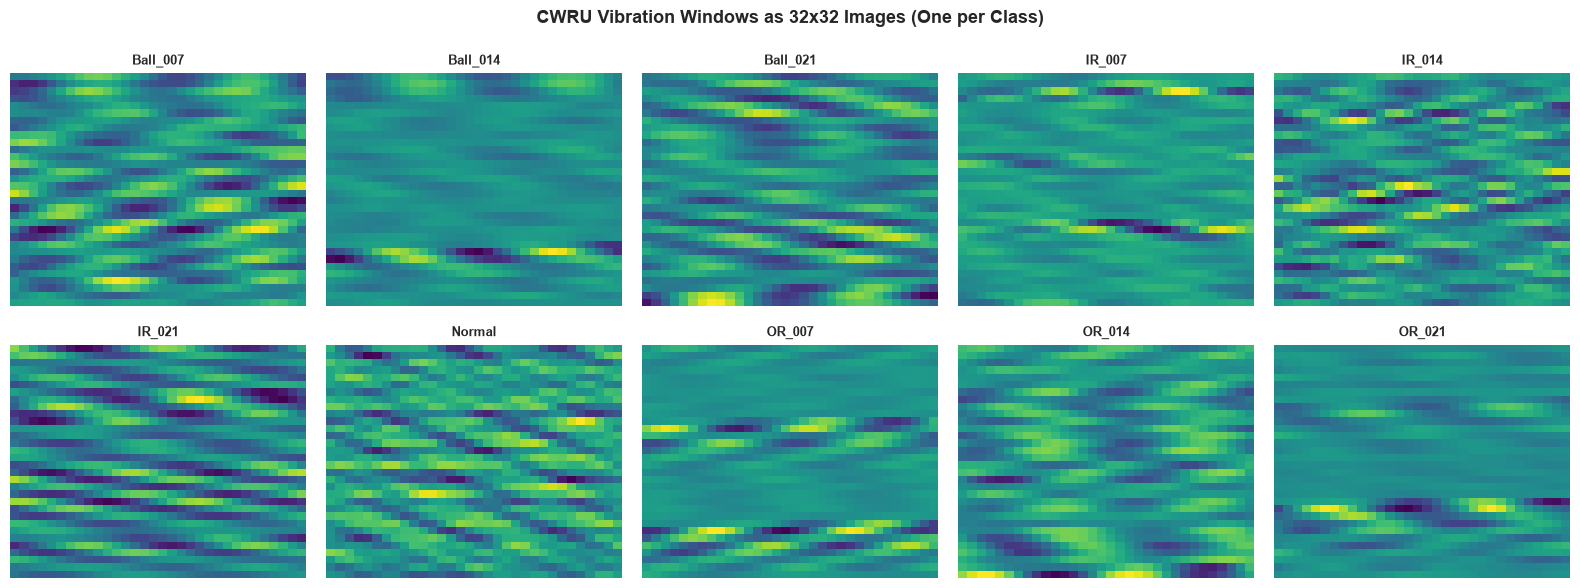


ℹ️ These 32x32 representations could feed a CNN, but VectoGuard
uses frequency features + GRU instead (better for temporal patterns).


In [22]:
# ============================================================
# 1.14 Load Pre-Windowed NPZ Data
# ============================================================

npz = np.load(os.path.join(CWRU_DIR, 'CWRU_48k_load_1_CNN_data.npz'), allow_pickle=True)
X_npz = npz['data']
y_npz = npz['labels']

print(f"NPZ Data shape: {X_npz.shape}  (samples x height x width)")
print(f"NPZ Labels shape: {y_npz.shape}")
print(f"\nLabel distribution:")
unique, counts = np.unique(y_npz, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  {label:10s}: {count} samples")

# Visualize a few samples as 2D images
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for i, label in enumerate(unique):
    ax = axes[i // 5][i % 5]
    idx = np.where(y_npz == label)[0][0]  # first sample of this class
    ax.imshow(X_npz[idx], cmap='viridis', aspect='auto')
    ax.set_title(label, fontsize=9, fontweight='bold')
    ax.axis('off')

plt.suptitle('CWRU Vibration Windows as 32x32 Images (One per Class)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n\u2139\ufe0f These 32x32 representations could feed a CNN, but VectoGuard")
print("uses frequency features + GRU instead (better for temporal patterns).")

## 1.15 EDA Summary — Key Findings

This section summarizes everything we discovered and what it means for the next notebooks.

### Sensor Domain (CWRU Bearing Data)

| Finding | Implication | Action |
|---------|------------|--------|
| 10 balanced classes (230 each) | No class weighting needed | ✅ Standard split |
| No missing values | No imputation needed | ✅ Clean |
| RMS & Kurtosis strongly differentiate faults | Good candidate features | → Feature engineering (NB3) |
| Vibration distributions are skewed | May benefit from Power Transformer | → Preprocessing (NB2) |
| Some features highly correlated (sd ↔ rms) | Redundancy | → Feature selection (NB3) |
| FFT reveals clear fault-characteristic frequencies | Frequency features are essential | → Sliding-DFT (NB5) |
| Higher severity = larger frequency peaks | Severity detection is feasible | → GRU + Attention (NB6) |
| Outliers in features are fault-related, not noise | Don't remove — use RobustScaler | → Scaling (NB3) |

### Cloud Domain (Synthetic Metrics)

| Finding | Implication | Action |
|---------|------------|--------|
| Latency is right-skewed | Needs log transform | → Preprocessing (NB2) |
| Metrics are correlated during anomaly | Multi-variate detection needed | → Wavelet Transformer (NB9) |
| Normal vs anomaly clearly separable | Good baseline separability | ✅ |
| Different metrics have different scales | Must normalize | → Scaling (NB3) |

In [23]:
# ============================================================
# 1.15 Save Processed Data for Notebook 2
# ============================================================

# Create output directories
os.makedirs(os.path.join(DATA_DIR, 'processed'), exist_ok=True)
os.makedirs(os.path.join(DATA_DIR, 'synthetic'), exist_ok=True)

# Save sensor features CSV
df_features.to_csv(os.path.join(DATA_DIR, 'processed', 'cwru_features.csv'), index=False)
print(f"\u2705 Saved sensor features: {os.path.join(DATA_DIR, 'processed', 'cwru_features.csv')}")
print(f"   Shape: {df_features.shape}")

# Save raw data info (which .mat files, labels, sample counts)
raw_info = []
for label, entry in raw_data.items():
    raw_info.append({
        'label': label,
        'filename': entry['filename'],
        'de_samples': len(entry['de']) if entry['de'] is not None else 0,
        'fe_samples': len(entry['fe']) if entry['fe'] is not None else 0,
        'rpm': entry['rpm'],
    })
df_raw_info = pd.DataFrame(raw_info)
df_raw_info.to_csv(os.path.join(DATA_DIR, 'processed', 'cwru_raw_info.csv'), index=False)
print(f"\u2705 Saved raw data info: {os.path.join(DATA_DIR, 'processed', 'cwru_raw_info.csv')}")

# Save cloud metrics
df_cloud.to_csv(os.path.join(DATA_DIR, 'synthetic', 'cloud_metrics.csv'), index=False)
print(f"\u2705 Saved cloud metrics: {os.path.join(DATA_DIR, 'synthetic', 'cloud_metrics.csv')}")
print(f"   Shape: {df_cloud.shape}")

# Save NPZ label mapping for reference
npz_info = pd.DataFrame({'label': unique, 'count': counts})
npz_info.to_csv(os.path.join(DATA_DIR, 'processed', 'npz_label_info.csv'), index=False)
print(f"\u2705 Saved NPZ label info")

print(f"\n{'='*60}")
print("All data saved. Ready for Notebook 2 (Preprocessing).")
print(f"{'='*60}")

✅ Saved sensor features: d:\NIAI_NAVTTC\project_ideas\Vecto_Guard\Vecto_Guard\data\processed\cwru_features.csv
   Shape: (2300, 12)
✅ Saved raw data info: d:\NIAI_NAVTTC\project_ideas\Vecto_Guard\Vecto_Guard\data\processed\cwru_raw_info.csv
✅ Saved cloud metrics: d:\NIAI_NAVTTC\project_ideas\Vecto_Guard\Vecto_Guard\data\synthetic\cloud_metrics.csv
   Shape: (1200, 8)
✅ Saved NPZ label info

All data saved. Ready for Notebook 2 (Preprocessing).


## Next Steps

| Notebook | What Comes Next |
|----------|----------------|
| **02_Preprocessing** | Function Transformer, Power Transformer, Ordinal/One-Hot Encoding, Column Transformer, Binning |
| **03_Scaling_Features** | Standardization, Normalization, Feature Construction (time + frequency), Feature Selection, PCA |
| **04_Pipeline_Foundation** | DataPacket, SystemState, Lifecycle, Brain interface, Router, RuntimeState |

---

**End of Notebook 1: EDA Complete ✅**